In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import models
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report

# Cek ketersediaan GPU
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Device yang digunakan: {device}")

Device yang digunakan: cuda:0


In [2]:
# Transformasi data: Resize ke 224x224 (ukuran ideal ResNet) dan normalisasi
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
])

# Load seluruh dataset CIFAR-10
full_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)

# Membagi dataset menjadi 80% Training dan 20% Validation
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(full_dataset, [train_size, val_size])

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
print(f"Jumlah Data Training: {len(train_dataset)}")
print(f"Jumlah Data Validation: {len(val_dataset)}")

100%|██████████| 170M/170M [34:55<00:00, 81.3kB/s]


Jumlah Data Training: 40000
Jumlah Data Validation: 10000


In [3]:
# Load Pretrained Model ResNet18
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Modifikasi Top Layer (Classifier Head)
num_ftrs = model.fc.in_features
# Mengganti fully connected layer terakhir agar sesuai jumlah kelas (10)
model.fc = nn.Linear(num_ftrs, 10)

model = model.to(device)
print(model.fc) # Menampilkan layer yang sudah dimodifikasi

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 174MB/s]


Linear(in_features=512, out_features=10, bias=True)


In [4]:
criterion = nn.CrossEntropyLoss()
# Menggunakan Adam dengan Learning Rate rendah (1e-4) untuk Fine-Tuning
optimizer = optim.Adam(model.parameters(), lr=1e-4)

epochs = 5
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

for epoch in range(epochs):
    # --- FASE TRAINING ---
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # --- FASE VALIDATION ---
    model.eval()
    val_loss, correct_val, total_val = 0.0, 0, 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total_val += labels.size(0)
            correct_val += predicted.eq(labels).sum().item()

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = correct_val / total_val
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}")

Epoch 1/5 | Train Loss: 0.3654 Acc: 0.8793 | Val Loss: 0.2024 Acc: 0.9314
Epoch 2/5 | Train Loss: 0.1324 Acc: 0.9567 | Val Loss: 0.1775 Acc: 0.9410
Epoch 3/5 | Train Loss: 0.0724 Acc: 0.9768 | Val Loss: 0.1930 Acc: 0.9367
Epoch 4/5 | Train Loss: 0.0521 Acc: 0.9832 | Val Loss: 0.2208 Acc: 0.9336
Epoch 5/5 | Train Loss: 0.0430 Acc: 0.9857 | Val Loss: 0.2168 Acc: 0.9340


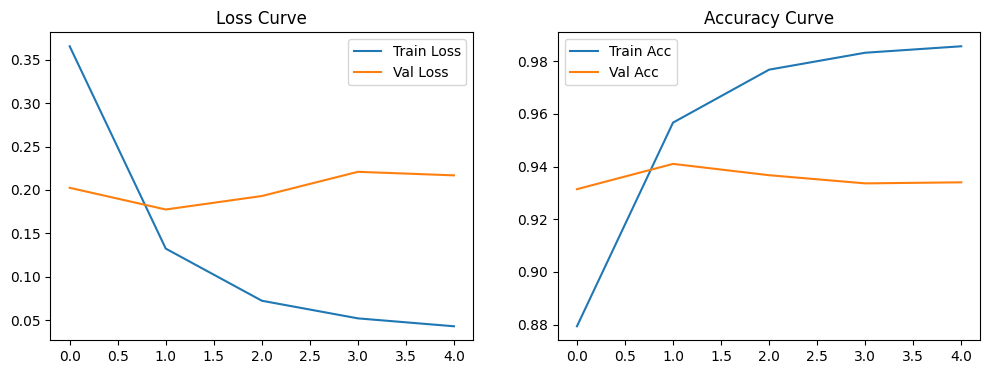


=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

       plane       0.91      0.97      0.94       987
         car       0.95      0.98      0.96       999
        bird       0.92      0.90      0.91       996
         cat       0.87      0.87      0.87       998
        deer       0.92      0.95      0.93       978
         dog       0.88      0.91      0.89      1026
        frog       0.96      0.96      0.96       997
       horse       0.98      0.91      0.95       984
        ship       0.98      0.95      0.96      1014
       truck       0.97      0.95      0.96      1021

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



In [5]:
# 1. Plot Kurva Akurasi dan Loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_losses, label='Train Loss')
axes[0].plot(val_losses, label='Val Loss')
axes[0].set_title('Loss Curve')
axes[0].legend()

axes[1].plot(train_accuracies, label='Train Acc')
axes[1].plot(val_accuracies, label='Val Acc')
axes[1].set_title('Accuracy Curve')
axes[1].legend()
plt.show()

# 2. Classification Report
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(all_labels, all_preds, target_names=classes))